# Cell 1: Auto-Detect Paths & Calibrate PCU Thresholds


In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 kB 737.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 kB 4.0 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Hunting for mounted datasets and model weights...
Success! Found model at: /kaggle/input/datasets/sharminaktermukta/yolov11-weight/best.pt
Success! Found Validation folder at: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/val/images
Calculating traffic density across the validation set...


100%|██████████| 1000/1000 [01:53<00:00,  8.80it/s]



--- Dynamic Congestion Thresholds ---
Low Congestion   : 0.0 to 7.88 PCU
Medium Congestion: 7.88 to 14.83 PCU
High Congestion  : > 14.83 PCU


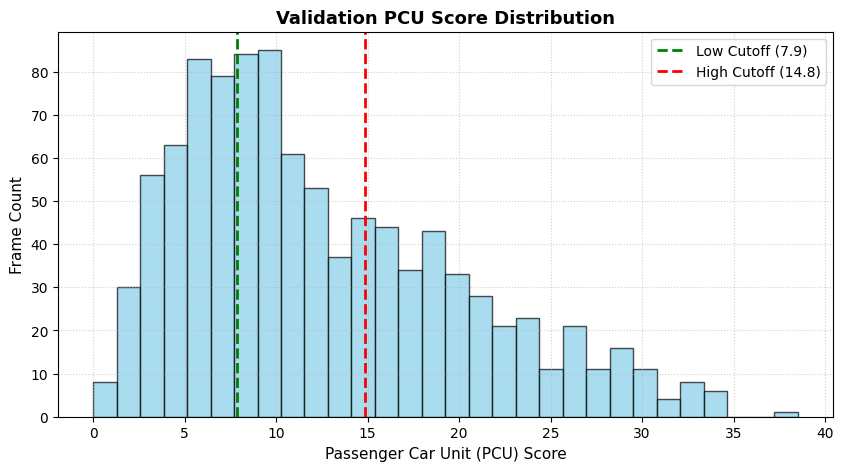

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import requests
from ultralytics import YOLO
from tqdm import tqdm

print("Hunting for mounted datasets and model weights...")

# 1. Auto-Detect the Model Weights (best.pt)
MODEL_PATH = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'best.pt' in files:
        MODEL_PATH = os.path.join(root, 'best.pt')
        break

if not MODEL_PATH:
    raise FileNotFoundError("Could not find 'best.pt'. Make sure it is added via 'Add Input'.")
print(f"Success! Found model at: {MODEL_PATH}")

# 2. Auto-Detect the Validation Images Directory
VAL_IMAGES_DIR = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'tfp_dataset' in dirs:
        VAL_IMAGES_DIR = os.path.join(root, 'tfp_dataset', 'val', 'images')
        break

if not VAL_IMAGES_DIR or not os.path.exists(VAL_IMAGES_DIR):
    raise FileNotFoundError("Could not find the 'val/images' folder. Check your mounted inputs.")
print(f"Success! Found Validation folder at: {VAL_IMAGES_DIR}")

# 3. Load Model and Fetch Images
model = YOLO(MODEL_PATH)
val_images = [os.path.join(VAL_IMAGES_DIR, f) for f in os.listdir(VAL_IMAGES_DIR) if f.endswith(('.jpg', '.png', '.jpeg'))]

# 4. PCU Weights Dictionary for the 9 Target Classes (Global Variable)
PCU_WEIGHTS = {
    'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5,
    'CNG': 0.75, 'Rickshaw': 0.8, 'Motorcycle': 0.4, 'Bicycle': 0.3, 'Pedestrian': 0.0
}

# 5. Compute PCU Score Distribution
pcu_scores = []
print("Calculating traffic density across the validation set...")

for img_path in tqdm(val_images[:1000]):  
    results = model.predict(source=img_path, conf=0.35, verbose=False)[0]
    frame_pcu = 0.0
    for box in results.boxes:
        cls_name = results.names[int(box.cls[0].item())]
        frame_pcu += PCU_WEIGHTS.get(cls_name, 0.5)
    pcu_scores.append(frame_pcu)

pcu_scores = np.array(pcu_scores)

# 6. Extract Statistical Percentile Cutoffs (Tertiles)
low_cutoff = np.percentile(pcu_scores, 33.3)
high_cutoff = np.percentile(pcu_scores, 66.6)

print(f"\n--- Dynamic Congestion Thresholds ---")
print(f"Low Congestion   : 0.0 to {low_cutoff:.2f} PCU")
print(f"Medium Congestion: {low_cutoff:.2f} to {high_cutoff:.2f} PCU")
print(f"High Congestion  : > {high_cutoff:.2f} PCU")

# 7. Generate Distribution Visual
plt.figure(figsize=(10, 5))
plt.hist(pcu_scores, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(low_cutoff, color='green', linestyle='--', linewidth=2, label=f'Low Cutoff ({low_cutoff:.1f})')
plt.axvline(high_cutoff, color='red', linestyle='--', linewidth=2, label=f'High Cutoff ({high_cutoff:.1f})')
plt.title('Validation PCU Score Distribution', fontsize=13, fontweight='bold')
plt.xlabel('Passenger Car Unit (PCU) Score', fontsize=11)
plt.ylabel('Frame Count', fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Cell 2: Supercharged Internet Inference (Test Time Augmentation)


In [3]:
!pip install sahi -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.6/156.6 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 4.9 MB/s eta 0:00:00


Hunting for model weights...

--- Processing Image 1/3 ---
Scout detected 17 objects. Routing to Standard Inference...
Success! Annotated image saved to: /kaggle/working/dynamic_test_ANALYZED_1.jpg


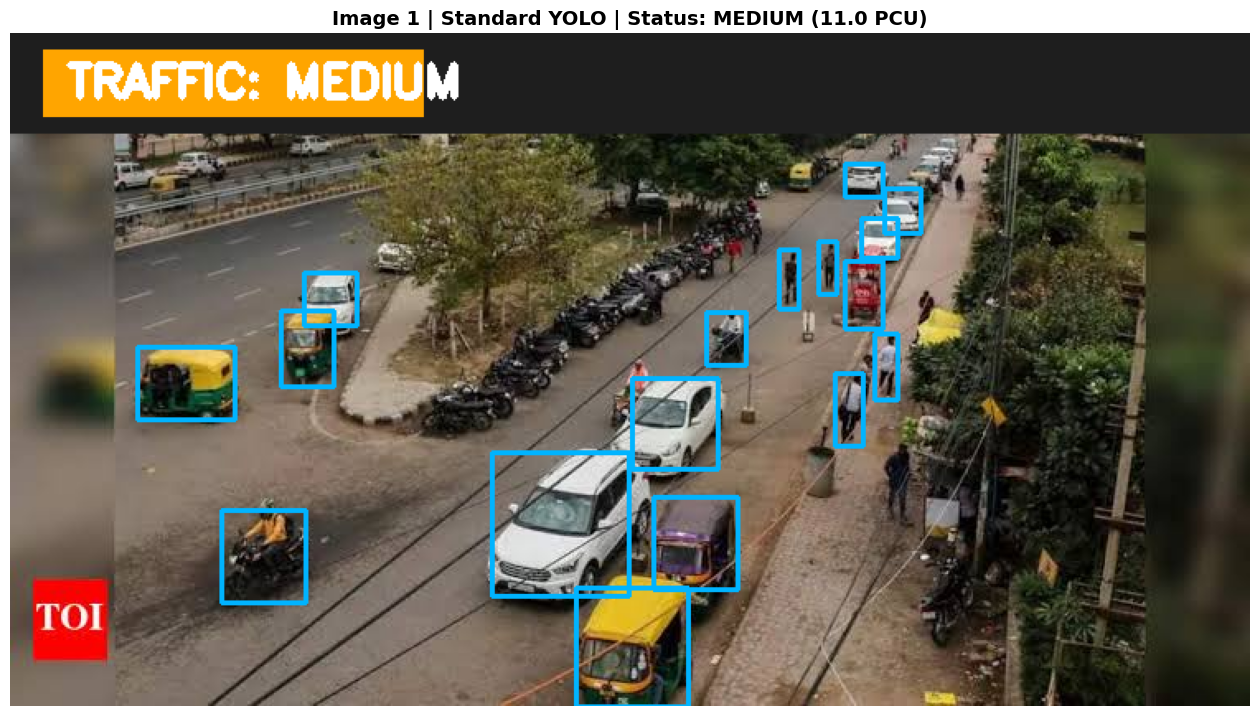


--- Processing Image 2/3 ---
Scout detected 19 objects. Routing to Standard Inference...
Success! Annotated image saved to: /kaggle/working/dynamic_test_ANALYZED_2.jpg


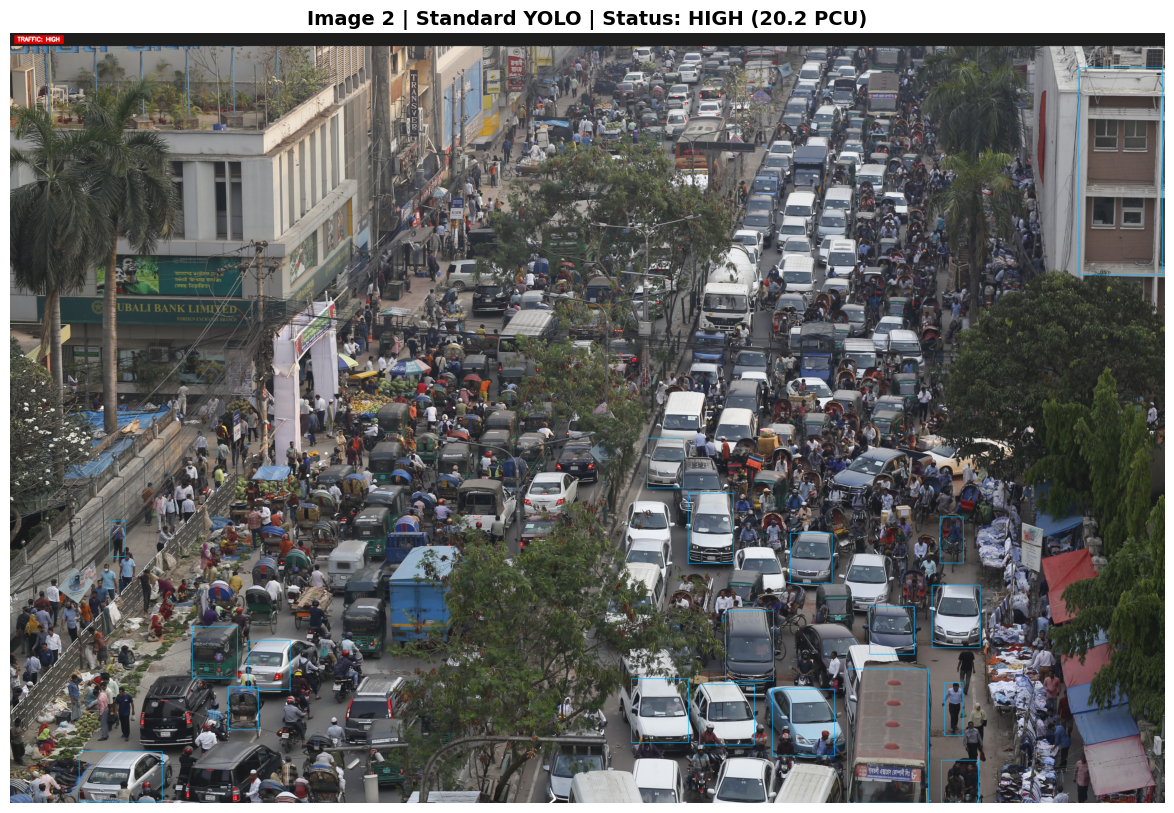


--- Processing Image 3/3 ---
Scout detected 2 objects. Routing to Standard Inference...
Success! Annotated image saved to: /kaggle/working/dynamic_test_ANALYZED_3.jpg


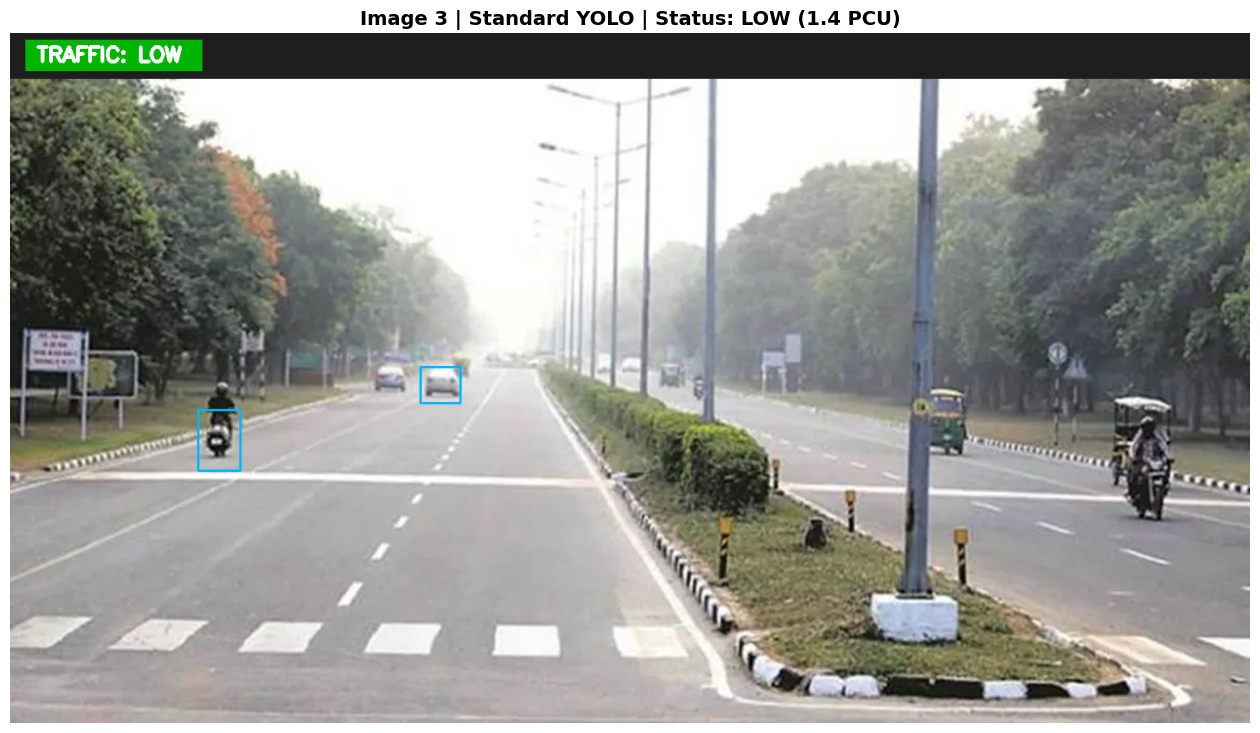

In [4]:
import os
import cv2
import requests
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

print("Hunting for model weights...")

MODEL_PATH = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'best.pt' in files:
        MODEL_PATH = os.path.join(root, 'best.pt')
        break

if not MODEL_PATH:
    raise FileNotFoundError("Could not find 'best.pt'. Make sure it is added via 'Add Input'.")

# PCU Weights and Thresholds mapped to your dataset
PCU_WEIGHTS = {
    'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5,
    'CNG': 0.75, 'Rickshaw': 0.8, 'Motorcycle': 0.4, 'Bicycle': 0.3, 'Pedestrian': 0.0
}
low_cutoff, high_cutoff = 8.45, 15.80

# Load both standard and SAHI models into memory
standard_model = YOLO(MODEL_PATH)
device_type = "cuda:0" if torch.cuda.is_available() else "cpu"
sahi_model = AutoDetectionModel.from_pretrained(
    model_type='yolov8', model_path=MODEL_PATH, confidence_threshold=0.18, device=device_type
)

def smart_traffic_analyzer(image_path):
    img = cv2.imread(image_path)
    h, w, _ = img.shape
    
    # 1. THE SCOUT PASS
    scout_results = standard_model.predict(source=image_path, conf=0.25, imgsz=1024, verbose=False)[0]
    num_scout_objects = len(scout_results.boxes)
    
    boxes_data = []
    
    # 2. AUTO-ROUTING LOGIC
    if num_scout_objects > 35:
        print(f"Scout detected {num_scout_objects} objects. Routing to SAHI Deep-Scan...")
        mode = "SAHI Macro-Zoom"
        
        result = get_sliced_prediction(
            image_path, sahi_model,
            slice_height=256, slice_width=256,
            overlap_height_ratio=0.4, overlap_width_ratio=0.4,
            postprocess_type="NMS", postprocess_match_threshold=0.4 
        )
        
        for obj in result.object_prediction_list:
            cls_name = obj.category.name
            if cls_name in PCU_WEIGHTS:
                bbox = obj.bbox
                boxes_data.append({'name': cls_name, 'xyxy': [int(bbox.minx), int(bbox.miny), int(bbox.maxx), int(bbox.maxy)]})
    else:
        print(f"Scout detected {num_scout_objects} objects. Routing to Standard Inference...")
        mode = "Standard YOLO"
        
        for box in scout_results.boxes:
            cls_name = scout_results.names[int(box.cls[0].item())]
            if cls_name in PCU_WEIGHTS:
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                boxes_data.append({'name': cls_name, 'xyxy': [x1, y1, x2, y2]})

    # 3. PCU CALCULATION
    total_pcu = 0.0
    for b in boxes_data:
        total_pcu += PCU_WEIGHTS.get(b['name'], 0.0)
        x1, y1, x2, y2 = b['xyxy']
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 180, 0), 2)

    # 4. Status Evaluation
    if total_pcu < low_cutoff:
        status, banner_color = "LOW", (0, 180, 0)      
    elif total_pcu <= high_cutoff:
        status, banner_color = "MEDIUM", (0, 165, 255)    
    else:
        status, banner_color = "HIGH", (0, 0, 220)      

    # 5. Overlay Minimalist HUD Banner
    cv2.rectangle(img, (0, 0), (w, 60), (30, 30, 30), -1)
    cv2.rectangle(img, (20, 10), (250, 50), banner_color, -1)
    cv2.putText(img, f"TRAFFIC: {status}", (35, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 3)

    return img, status, total_pcu, mode

# --- EXECUTION ---
# Replaced single string with a list of 3 URLs
IMAGE_URLS = [
    "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSXkkWJHQ-Rd5cKZVvuTBbBH5HTM2zKKpVW6HwTaBN4CwYznVnj9dMGh4E&s=10",
    "https://static.time.com/v3/assets/bltea6093859af6183b/bltd4c970056f6da5af/698a40c922fb856f5de2f1ba/Dhaka-traffic.jpg?branch=production", 
    "https://cf-img-a-in.tosshub.com/sites/visualstory/wp/2024/05/Chandigarh.webp?size=*:900"
]

headers = {'User-Agent': 'Mozilla/5.0'}

# Loop through each URL in the list
for i, url in enumerate(IMAGE_URLS):
    # Create unique filenames for each image using the index (i)
    download_path = f"/kaggle/working/dynamic_test_RAW_{i+1}.jpg"
    output_path = f"/kaggle/working/dynamic_test_ANALYZED_{i+1}.jpg" 

    print(f"\n--- Processing Image {i+1}/3 ---")
    print("Downloading image...")
    response = requests.get(url, headers=headers)
    with open(download_path, 'wb') as f:
        f.write(response.content)

    # Run inference
    rendered_frame, level, score, active_mode = smart_traffic_analyzer(download_path)

    # Save output
    cv2.imwrite(output_path, rendered_frame)
    print(f"Success! Annotated image saved to: {output_path}")

    # Plot the result
    plt.figure(figsize=(16, 10))
    plt.imshow(cv2.cvtColor(rendered_frame, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title(f"Image {i+1} | {active_mode} | Status: {level} ({score:.1f} PCU)", fontsize=14, fontweight='bold')
    plt.show()

# Cell 3: Real-Time Video Tracker

In [5]:
# 1. Locate the Uploaded Test Video Dynamically
INPUT_VIDEO = None
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file.endswith('.mp4'):
            INPUT_VIDEO = os.path.join(root, file)
            break
    if INPUT_VIDEO: break

if not INPUT_VIDEO:
    raise FileNotFoundError("Could not find an .mp4 file. Please upload a test video via 'Add Input'.")

OUTPUT_VIDEO = '/kaggle/working/traffic_analyzed.mp4'

# 2. Video Capture & Writer Setup
cap = cv2.VideoCapture(INPUT_VIDEO)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(OUTPUT_VIDEO, fourcc, fps, (width, height))

print(f"Processing Video: {INPUT_VIDEO} ({total_frames} frames)")

# 3. Frame-by-Frame Processing Loop
frame_count = 0

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
        
    frame_count += 1
    if frame_count % 30 == 0:
        print(f"Processing frame {frame_count}/{total_frames}...")

    # Standard inference for video (TTA is too slow for thousands of frames)
    results = model.predict(source=frame, conf=0.35, verbose=False)[0]
    total_pcu = 0.0
    
    # Draw detections
    for box in results.boxes:
        cls_id = int(box.cls[0].item())
        cls_name = results.names[cls_id]
        
        total_pcu += PCU_WEIGHTS.get(cls_name, 0.0)
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        
        cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 180, 0), 2)
        cv2.putText(frame, f"{cls_name}", (x1, max(20, y1 - 5)), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

    # Calculate status banner colors using the thresholds from Cell 1
    if total_pcu < low_cutoff:
        status, banner_color = "LOW", (0, 180, 0)
    elif total_pcu <= high_cutoff:
        status, banner_color = "MEDIUM", (0, 165, 255)
    else:
        status, banner_color = "HIGH", (0, 0, 220)

    # Render HUD Overlay
    cv2.rectangle(frame, (0, 0), (width, 60), (30, 30, 30), -1)
    cv2.rectangle(frame, (20, 12), (180, 48), banner_color, -1)
    
    cv2.putText(frame, f"TRAFFIC: {status}", (30, 37), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    cv2.putText(frame, f"Total PCU: {total_pcu:.2f} | Objects: {len(results.boxes)}", 
                (200, 37), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (220, 220, 220), 2)

    out.write(frame)

cap.release()
out.release()
print(f"\nSuccess! Analyzed video saved to: {OUTPUT_VIDEO}")

Processing Video: /kaggle/input/datasets/sharminaktermukta/demo-video2/188613-883402208_medium.mp4 (660 frames)
Processing frame 30/660...
Processing frame 60/660...
Processing frame 90/660...
Processing frame 120/660...
Processing frame 150/660...
Processing frame 180/660...
Processing frame 210/660...
Processing frame 240/660...
Processing frame 270/660...
Processing frame 300/660...
Processing frame 330/660...
Processing frame 360/660...
Processing frame 390/660...
Processing frame 420/660...
Processing frame 450/660...
Processing frame 480/660...
Processing frame 510/660...
Processing frame 540/660...
Processing frame 570/660...
Processing frame 600/660...
Processing frame 630/660...
Processing frame 660/660...

Success! Analyzed video saved to: /kaggle/working/traffic_analyzed.mp4


PCU Weights: {'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5, 'CNG': 0.75, 'Motorcycle': 0.4, 'Rickshaw': 0.8, 'Bicycle': 0.3, 'Pedestrian': 0.0}
Low Threshold: 8.45
High Threshold: 15.8

Test Images: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/images
Test Labels: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/labels

Model Classes:
{0: 'Car', 1: 'Bus', 2: 'Truck', 3: 'Motorcycle', 4: 'Bicycle', 5: 'Rickshaw', 6: 'Mini-Truck', 7: 'CNG', 8: 'Pedestrian'}

Total Test Images: 2368
Images with missing labels: 0
Images with Ground Truth: 2368
Processed 100/2368 images
Processed 200/2368 images
Processed 300/2368 images
Processed 400/2368 images
Processed 500/2368 images
Processed 600/2368 images
Processed 700/2368 images
Processed 800/2368 images
Processed 900/2368 images
Processed 1000/2368 images
Processed 1100/2368 images
Processed 1200/2368 images
Processed 1300/2368 images
Processed 1400/2368 images
Processed 1500/23

,image,actual_pcu,predicted_pcu,actual_level,predicted_level
0,frame0_jpg.rf.2bdb52fd96f81bc52a55e5b5ce1ab3fd,14.55,19.05,MEDIUM,HIGH
1,frame0_jpg.rf.47f88bfa8857bb079cdaaffe6aa6ecd2,27.90,22.15,HIGH,HIGH
2,frame0_jpg.rf.9067d8476599d820a5497e7a4933764d,15.25,16.65,MEDIUM,HIGH
3,frame0_jpg.rf.b67d0effd101dedad76f7e39e2a02eb9,25.75,23.40,HIGH,HIGH
4,frame100_jpg.rf.f5d0a13c14dfb93b6678b392575a33dc,14.15,16.20,MEDIUM,HIGH


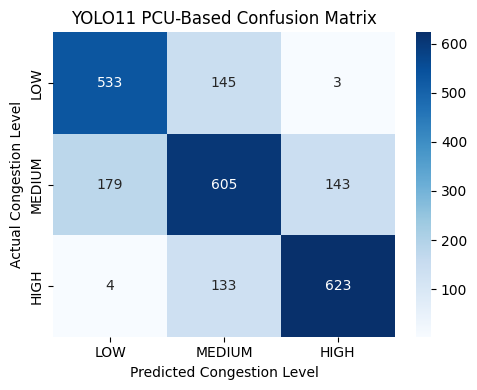


YOLO11 Classification Report:


,precision,recall,f1-score,support
LOW,0.7444,0.7827,0.7631,681.0000
MEDIUM,0.6852,0.6526,0.6685,927.0000
HIGH,0.8101,0.8197,0.8149,760.0000
accuracy,0.7437,0.7437,0.7437,0.7437
macro avg,0.7466,0.7517,0.7488,2368.0000
weighted avg,0.7423,0.7437,0.7427,2368.0000



YOLO11 PCU Congestion Accuracy: 74.37%

Final Metrics Table:


,precision,recall,f1-score,support
LOW,0.7444,0.7827,0.7631,681.0
MEDIUM,0.6852,0.6526,0.6685,927.0
HIGH,0.8101,0.8197,0.8149,760.0
Overall Accuracy,0.7437,0.7437,0.7437,2368.0



All files saved successfully in /kaggle/working/
1. yolo11_pcu_actual_predicted.csv
2. yolo11_pcu_classification_report.csv
3. yolo11_pcu_metrics_table.csv
4. yolo11_pcu_confusion_matrix.csv


In [6]:

# ============================================================
# YOLO11: PCU-BASED CONGESTION EVALUATION
# Same PCU Weights and Same Thresholds for All Models
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# ------------------------------------------------------------
# 1. SAME PCU WEIGHTS FOR ALL DETECTION MODELS
# ------------------------------------------------------------

PCU_WEIGHTS = {
    'Car': 1.0,
    'Bus': 3.0,
    'Truck': 3.0,
    'Mini-Truck': 1.5,
    'CNG': 0.75,
    'Motorcycle': 0.4,
    'Rickshaw': 0.8,
    'Bicycle': 0.3,
    'Pedestrian': 0.0
}

# ------------------------------------------------------------
# 2. SAME CONGESTION THRESHOLDS
# ------------------------------------------------------------

LOW_THRESHOLD = 8.45
HIGH_THRESHOLD = 15.80

def get_congestion_level(pcu):
    if pcu < LOW_THRESHOLD:
        return 'LOW'
    elif pcu <= HIGH_THRESHOLD:
        return 'MEDIUM'
    else:
        return 'HIGH'

print("PCU Weights:", PCU_WEIGHTS)
print("Low Threshold:", LOW_THRESHOLD)
print("High Threshold:", HIGH_THRESHOLD)

# ------------------------------------------------------------
# 3. TEST DATASET PATH
# ------------------------------------------------------------

# VAL_IMAGES_DIR comes from your previous Cell 1
DATASET_ROOT = os.path.dirname(os.path.dirname(VAL_IMAGES_DIR))

TEST_IMAGES_DIR = os.path.join(DATASET_ROOT, 'test', 'images')
TEST_LABELS_DIR = os.path.join(DATASET_ROOT, 'test', 'labels')

print("\nTest Images:", TEST_IMAGES_DIR)
print("Test Labels:", TEST_LABELS_DIR)

if not os.path.isdir(TEST_IMAGES_DIR):
    raise FileNotFoundError(f"Test images folder not found: {TEST_IMAGES_DIR}")

if not os.path.isdir(TEST_LABELS_DIR):
    raise FileNotFoundError(f"Test labels folder not found: {TEST_LABELS_DIR}")

# ------------------------------------------------------------
# 4. GET CLASS NAMES FROM TRAINED YOLO11 MODEL
# ------------------------------------------------------------

if isinstance(model.names, dict):
    class_names = model.names
else:
    class_names = dict(enumerate(model.names))

print("\nModel Classes:")
print(class_names)

# ------------------------------------------------------------
# 5. FIND TEST IMAGES
# ------------------------------------------------------------

image_extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp']
test_images = []

for ext in image_extensions:
    test_images.extend(
        glob.glob(os.path.join(TEST_IMAGES_DIR, ext))
    )

test_images = sorted(test_images)

print("\nTotal Test Images:", len(test_images))

if len(test_images) == 0:
    raise ValueError("No test images found!")

# ------------------------------------------------------------
# 6. CALCULATE GROUND TRUTH PCU FROM YOLO LABELS
# ------------------------------------------------------------

actual_pcu = {}
missing_labels = []

for img_path in test_images:

    image_name = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join(TEST_LABELS_DIR, image_name + '.txt')

    if not os.path.exists(label_path):
        missing_labels.append(image_name)
        continue

    frame_pcu = 0.0

    with open(label_path, 'r') as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()

        if len(parts) < 5:
            continue

        class_id = int(float(parts[0]))
        class_name = class_names.get(class_id)

        if class_name is None:
            continue

        frame_pcu += PCU_WEIGHTS.get(class_name, 0.0)

    actual_pcu[image_name] = frame_pcu

print("Images with missing labels:", len(missing_labels))
print("Images with Ground Truth:", len(actual_pcu))

# ------------------------------------------------------------
# 7. YOLO11 PREDICTION AND PREDICTED PCU
# ------------------------------------------------------------

results_data = []

for i, img_path in enumerate(test_images):

    image_name = os.path.splitext(os.path.basename(img_path))[0]

    if image_name not in actual_pcu:
        continue

    result = model.predict(
        source=img_path,
        conf=0.35,
        verbose=False
    )[0]

    predicted_pcu = 0.0

    if result.boxes is not None:
        for box in result.boxes:
            class_id = int(box.cls[0].item())
            class_name = class_names.get(class_id)

            if class_name is not None:
                predicted_pcu += PCU_WEIGHTS.get(class_name, 0.0)

    gt_pcu = actual_pcu[image_name]

    actual_level = get_congestion_level(gt_pcu)
    predicted_level = get_congestion_level(predicted_pcu)

    results_data.append({
        'image': image_name,
        'actual_pcu': gt_pcu,
        'predicted_pcu': predicted_pcu,
        'actual_level': actual_level,
        'predicted_level': predicted_level
    })

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(test_images)} images")

# ------------------------------------------------------------
# 8. CREATE RESULTS DATAFRAME
# ------------------------------------------------------------

df_results = pd.DataFrame(results_data)

if df_results.empty:
    raise ValueError("No evaluation results were generated!")

print("\nEvaluation Completed!")
print("Total Evaluated Images:", len(df_results))

display(df_results.head())

# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

labels = ['LOW', 'MEDIUM', 'HIGH']

y_true = df_results['actual_level']
y_pred = df_results['predicted_level']

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel('Predicted Congestion Level')
plt.ylabel('Actual Congestion Level')
plt.title('YOLO11 PCU-Based Confusion Matrix')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nYOLO11 Classification Report:")
display(report_df.round(4))

# ------------------------------------------------------------
# 11. ACCURACY
# ------------------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

print(f"\nYOLO11 PCU Congestion Accuracy: {accuracy * 100:.2f}%")

# ------------------------------------------------------------
# 12. PRECISION, RECALL, F1-SCORE AND SUPPORT TABLE
# ------------------------------------------------------------

metrics_table = report_df.loc[
    labels,
    ['precision', 'recall', 'f1-score', 'support']
].copy()

metrics_table.loc['Overall Accuracy'] = [
    accuracy,
    accuracy,
    accuracy,
    len(df_results)
]

print("\nFinal Metrics Table:")
display(metrics_table.round(4))

# ------------------------------------------------------------
# 13. SAVE RESULTS
# ------------------------------------------------------------

output_dir = '/kaggle/working'

df_results.to_csv(
    os.path.join(output_dir, 'yolo11_pcu_actual_predicted.csv'),
    index=False
)

report_df.to_csv(
    os.path.join(output_dir, 'yolo11_pcu_classification_report.csv')
)

metrics_table.to_csv(
    os.path.join(output_dir, 'yolo11_pcu_metrics_table.csv')
)

pd.DataFrame(
    cm,
    index=labels,
    columns=labels
).to_csv(
    os.path.join(output_dir, 'yolo11_pcu_confusion_matrix.csv')
)

print("\nAll files saved successfully in /kaggle/working/")
print("1. yolo11_pcu_actual_predicted.csv")
print("2. yolo11_pcu_classification_report.csv")
print("3. yolo11_pcu_metrics_table.csv")
print("4. yolo11_pcu_confusion_matrix.csv")
